In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [3]:
cpu = pd.read_csv("../challenge_data/vm_cpu_readings.csv.gz")

In [4]:
cpu

,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588
3,0,/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...,1.939634,3.228830,2.374714
4,0,wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...,0.352236,0.855003,0.597535
...,...,...,...,...,...
1339995,39900,GI1NSfZ3RtVtCCax6F69SEYBZPDvGr3l05bneutjReACJv...,3.570585,12.568878,5.993970
1339996,39900,4sQlZ1VeuUk5zAdkNFjxaXEsI3ROLZtFzOMiuDleoQOmKn...,4.925697,19.473381,8.539113
1339997,39900,BytpDwExOQ93bgjfsVJxqQFepypm0VC99Z2m8s+OMyZSUN...,5.328881,53.948870,14.746790
1339998,39900,aDokW2s1f3+IYoSTWTIC7JtuEAQ7ACncN2BsZZO7E6506u...,3.607924,4.336126,4.033910


In [5]:
meta = pd.read_csv("../challenge_data/vm_metadata.csv.gz")

In [6]:
meta

,vm_id,subscription_id,deployment_id,timestamp_vm_created,timestamp_vm_deleted,max_cpu,avg_cpu,p95_max_cpu,vm_category,virtual_core_bucket,memory_gb_bucket
0,FpzMJdMf8qtHmtOG8tkLZzGwGyipMwLXrWaOB9t83llPSU...,zidmVREtoQ8LZn7hurMi6cpBzixgqQWaYI1dDjz+KHaLRE...,gFCpVCrXZfTE26Jz92rA1lBddtl3tjwT0DKwPsxVITF73e...,0,2591400,76.317105,4.770387,8.491848,Delay-insensitive,2,2
1,BH2lz1WPrkc3OhPzE5+mecvo3sum6s14EvcZLFN/lqH9w4...,JOJ5q+T2F5zCr4CzSwPxfZgGVFfdKdzjjyZYGRu6hnomvn...,+qsl6upF4G6CBnFVK97vb0yE1lC551CWp9U1lcfnZKmz1Q...,0,406200,96.755318,0.699635,23.814289,Unknown,8,64
2,vstJO/1LuWKseZPzWayfdckE5FnkWLmqaWziPASYuJdPoh...,0kctkGk351EZ4Sj1AIzheqbGJ5hlYjCbuyZHXtr8PT2Ubg...,TJuS+gMfk5LBg0+dHsOwoQdDyYYCu7YS60KJkeVuxOyaEN...,0,2591400,83.110403,5.878783,11.293819,Delay-insensitive,2,4
3,88rAudRS2akNM+S6uHDTXAq6YE+1z27wota+723juDdmcY...,4qyOW7DwhjSolTnKK27cY1ELmu2hqpBNkgiHsfTOex2UUb...,yfPM2qpoqC9aXMgM7S0mCLxCY8NEd4C6uiLpfY443SV5Yj...,0,70200,98.738842,81.578650,98.439173,Unknown,4,8
4,C+lO8PpCWNqnq5dIhv4Mu74NxH8HHYC0/EKOatNq6YHe04...,1PDByEqjMhhy8jWbS/5ttawogqgyACcOAWYVk3rbt3ouVU...,hrP166UPejKeASJ3ibhQ68YrE7iDxsmlXNZ2B8BBy0BMKn...,0,2591400,90.790129,2.382323,6.902215,Delay-insensitive,2,4
...,...,...,...,...,...,...,...,...,...,...,...
9995,V1UW2m2QiAQ0fVH+1IsOg98UPRUh5Tp3irbOfGgavUlzgj...,XEEvbhr2HDomhvdVW+vePd818nAOoH4kiGEgH27U4jx7Gg...,evm+bgv9DZ+BcinVtitD98ONTDp02exy6Ex8sJdNnr2GJI...,0,2591400,37.318018,1.980718,13.544121,Delay-insensitive,2,8
9996,lkyI4YOJFS9rSPiF1JT3CO5TrbsrmpTDP5GgcC1Ahz9gLh...,CjGWdhWCUFulUDu7vtxG55SyARn6VNrqtAhpoac4R4Y2Th...,YviKkyG8rnJZEFXqX7l/kvGRLzruNtxbFK0OD2CxyqqhV3...,0,245700,95.438722,11.520593,63.119524,Unknown,4,32
9997,H5pD4GBGHiMs0DM9qWTbxBygPnTN/FDDv4WnsI7d91RI67...,lVU+ctg65xo/7LLBNBTj2N5ARIXfn5P8313kBvONZBmwwL...,6hVLU0a+rBisTmr34+ybxfLZbTyquhH4I5KfPXRyxh3z3+...,0,2591400,98.708111,6.890281,15.792041,Delay-insensitive,2,2
9998,+inzx958YwVlHaEIWbirxUfddHwR9aaPCMz8x1mNn9fDoT...,h30IXlTWGg9PJDDgaz2cuKx6LNP4yffl12TEVpTJ/xErse...,ALf1+FpHszm6Sm5QL6Dl1QwQgcPDbNVl0FfohvOcxpcqdV...,0,2591400,65.580680,1.842422,6.201421,Interactive,4,32


In [7]:
print(cpu.shape, meta.shape)

(1340000, 5) (10000, 11)


In [8]:
print(cpu.head())

   timestamp                                              vm_id   min_cpu  \
0          0  H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...  1.812194   
1          0  pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...  4.126021   
2          0  iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...  1.225669   
3          0  /f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...  1.939634   
4          0  wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...  0.352236   

     max_cpu   avg_cpu  
0  14.587021  4.851659  
1   5.650850  4.687886  
2   2.082111  1.607588  
3   3.228830  2.374714  
4   0.855003  0.597535  


In [9]:
print(cpu.dtypes)

timestamp      int64
vm_id            str
min_cpu      float64
max_cpu      float64
avg_cpu      float64
dtype: object


In [10]:
print(meta.head())

                                               vm_id  \
0  FpzMJdMf8qtHmtOG8tkLZzGwGyipMwLXrWaOB9t83llPSU...   
1  BH2lz1WPrkc3OhPzE5+mecvo3sum6s14EvcZLFN/lqH9w4...   
2  vstJO/1LuWKseZPzWayfdckE5FnkWLmqaWziPASYuJdPoh...   
3  88rAudRS2akNM+S6uHDTXAq6YE+1z27wota+723juDdmcY...   
4  C+lO8PpCWNqnq5dIhv4Mu74NxH8HHYC0/EKOatNq6YHe04...   

                                     subscription_id  \
0  zidmVREtoQ8LZn7hurMi6cpBzixgqQWaYI1dDjz+KHaLRE...   
1  JOJ5q+T2F5zCr4CzSwPxfZgGVFfdKdzjjyZYGRu6hnomvn...   
2  0kctkGk351EZ4Sj1AIzheqbGJ5hlYjCbuyZHXtr8PT2Ubg...   
3  4qyOW7DwhjSolTnKK27cY1ELmu2hqpBNkgiHsfTOex2UUb...   
4  1PDByEqjMhhy8jWbS/5ttawogqgyACcOAWYVk3rbt3ouVU...   

                                       deployment_id  timestamp_vm_created  \
0  gFCpVCrXZfTE26Jz92rA1lBddtl3tjwT0DKwPsxVITF73e...                     0   
1  +qsl6upF4G6CBnFVK97vb0yE1lC551CWp9U1lcfnZKmz1Q...                     0   
2  TJuS+gMfk5LBg0+dHsOwoQdDyYYCu7YS60KJkeVuxOyaEN...                     0   
3  yfPM2qpoqC9

In [11]:
print(meta.dtypes)

vm_id                       str
subscription_id             str
deployment_id               str
timestamp_vm_created      int64
timestamp_vm_deleted      int64
max_cpu                 float64
avg_cpu                 float64
p95_max_cpu             float64
vm_category                 str
virtual_core_bucket         str
memory_gb_bucket            str
dtype: object


In [13]:
ts = np.sort(cpu["timestamp"].unique())
print("unique timestamps:", len(ts))
print("first, last:", ts[0], ts[-1])

gaps = pd.Series(np.diff(ts))
print(gaps.value_counts())  

unique timestamps: 134
first, last: 0 39900
300    133
Name: count, dtype: int64


In [14]:
ts_index = {t: i for i, t in enumerate(ts)}
cpu["step"] = cpu["timestamp"].map(ts_index)
cpu["split"] = np.where(cpu["step"] < 110, "train", "holdout")

count    10000.0
mean       134.0
std          0.0
min        134.0
25%        134.0
50%        134.0
75%        134.0
max        134.0
dtype: float64
count      134.0
mean     10000.0
std          0.0
min      10000.0
25%      10000.0
50%      10000.0
75%      10000.0
max      10000.0
dtype: float64


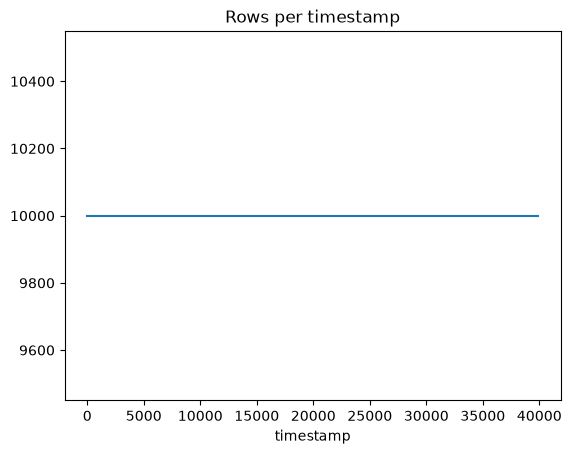

In [15]:
rows_per_vm = cpu.groupby("vm_id").size()
print(rows_per_vm.describe())

rows_per_ts = cpu.groupby("timestamp").size()
print(rows_per_ts.describe())
rows_per_ts.plot(title="Rows per timestamp"); plt.show()

In [16]:
# missing values
print(cpu.isna().sum())

# duplicates: same VM at the same timestamp more than once
dup = cpu.duplicated(subset=["vm_id", "timestamp"]).sum()
print("duplicate (vm_id, timestamp) rows:", dup)

# impossible values
print((cpu["avg_cpu"] < 0).sum(), (cpu["avg_cpu"] > 100).sum())

# logical check: min <= avg <= max
bad = ((cpu["min_cpu"] > cpu["avg_cpu"]) | (cpu["avg_cpu"] > cpu["max_cpu"])).sum()
print("rows where min<=avg<=max is violated:", bad)

# VMs in readings but missing from metadata (and the reverse)
print(len(set(cpu.vm_id) - set(meta.vm_id)), len(set(meta.vm_id) - set(cpu.vm_id)))

timestamp    0
vm_id        0
min_cpu      0
max_cpu      0
avg_cpu      0
step         0
split        0
dtype: int64
duplicate (vm_id, timestamp) rows: 0
0 0
rows where min<=avg<=max is violated: 0
0 0


       first_step  last_step    n_obs
count     10000.0    10000.0  10000.0
mean          0.0      133.0    134.0
std           0.0        0.0      0.0
min           0.0      133.0    134.0
25%           0.0      133.0    134.0
50%           0.0      133.0    134.0
75%           0.0      133.0    134.0
max           0.0      133.0    134.0


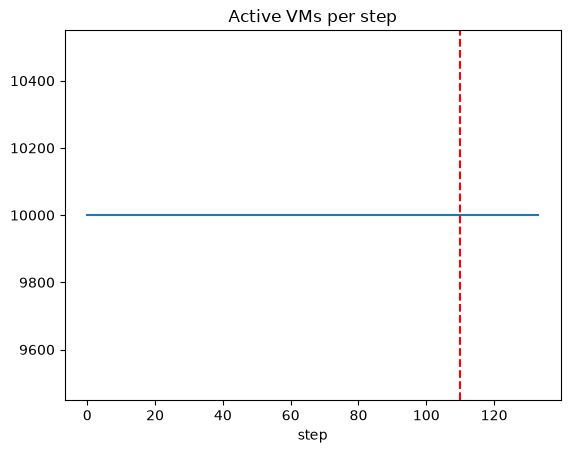

In [17]:
# when does each VM first/last appear in the readings?
life = cpu.groupby("vm_id")["step"].agg(first_step="min", last_step="max", n_obs="count")
print(life.describe())

# VMs starting and ending per time step
starts = life["first_step"].value_counts().sort_index()
ends = life["last_step"].value_counts().sort_index()

# active count per step
active = cpu.groupby("step")["vm_id"].nunique()
active.plot(title="Active VMs per step"); plt.axvline(110, color="r", ls="--"); plt.show()

In [18]:
df = meta.copy()
df["lifetime_hours"] = (df["timestamp_vm_deleted"] - df["timestamp_vm_created"]) / 3600
print(df["lifetime_hours"].describe())

count    10000.000000
mean       636.007117
std        196.694676
min         11.250000
25%        719.833333
50%        719.833333
75%        719.833333
max        719.833333
Name: lifetime_hours, dtype: float64


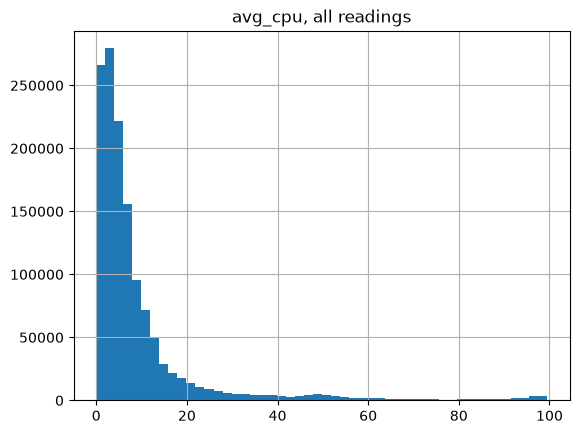

count    1.340000e+06
mean     9.388101e+00
std      1.426601e+01
min      7.158922e-03
5%       7.747083e-01
25%      2.477060e+00
50%      5.105133e+00
75%      9.616715e+00
95%      3.713295e+01
99%      8.735109e+01
max      9.948803e+01
Name: avg_cpu, dtype: float64


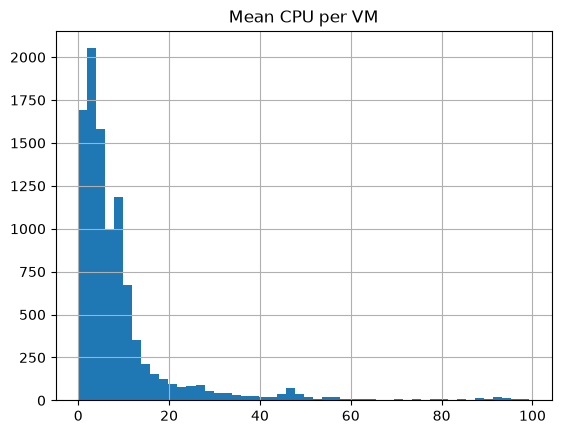

share of VMs with mean CPU < 5%: 0.4643
share of VMs with mean CPU > 50%: 0.0221


In [19]:
cpu["avg_cpu"].hist(bins=50); plt.title("avg_cpu, all readings"); plt.show()
print(cpu["avg_cpu"].describe(percentiles=[.05, .25, .5, .75, .95, .99]))

per_vm = cpu.groupby("vm_id")["avg_cpu"].mean()
per_vm.hist(bins=50); plt.title("Mean CPU per VM"); plt.show()

print("share of VMs with mean CPU < 5%:", (per_vm < 5).mean())
print("share of VMs with mean CPU > 50%:", (per_vm > 50).mean())

In [20]:
cpu["burst_gap"] = cpu["max_cpu"] - cpu["avg_cpu"]
print(cpu["burst_gap"].describe())

count    1.340000e+06
mean     8.960195e+00
std      1.279115e+01
min      0.000000e+00
25%      1.230882e+00
50%      3.281828e+00
75%      1.065351e+01
max      9.552098e+01
Name: burst_gap, dtype: float64


In [21]:
agg = cpu.groupby("step").agg(
    active_vm_count=("vm_id", "nunique"),
    cpu_mean=("avg_cpu", "mean"),
    cpu_p50=("avg_cpu", "median"),
    cpu_p95=("avg_cpu", lambda s: s.quantile(0.95)),
)
train = agg.iloc[:110]    # use ONLY this for pattern conclusions

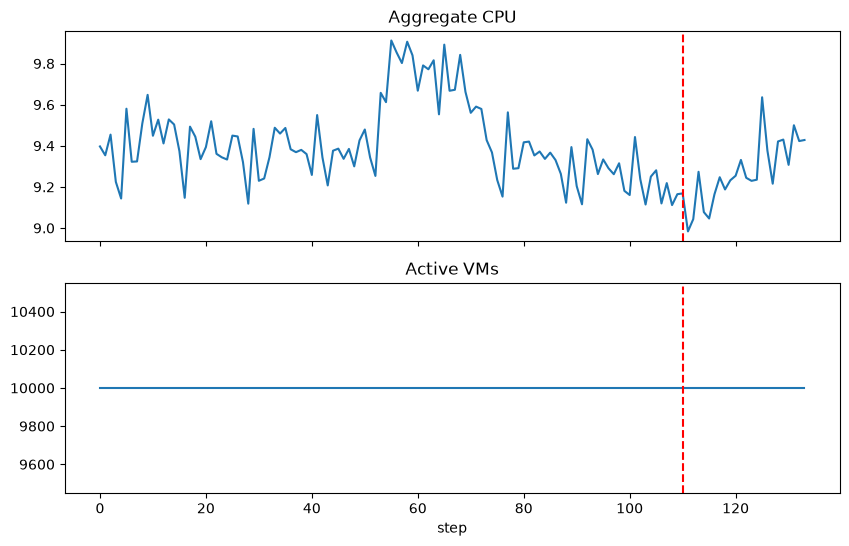

In [22]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
agg["cpu_mean"].plot(ax=ax[0]); ax[0].axvline(110, color="r", ls="--"); ax[0].set_title("Aggregate CPU")
agg["active_vm_count"].plot(ax=ax[1]); ax[1].axvline(110, color="r", ls="--"); ax[1].set_title("Active VMs")
plt.show()

In [23]:
s = train["cpu_mean"]
for lag in [1, 2, 3, 6, 12, 24]:
    print(lag, round(s.autocorr(lag), 3))

1 0.667
2 0.606
3 0.681
6 0.477
12 0.367
24 -0.026


In [24]:
s.diff().describe()

count    109.000000
mean      -0.002132
std        0.158033
min       -0.274332
25%       -0.109190
50%       -0.020451
75%        0.078342
max        0.436831
Name: cpu_mean, dtype: float64

In [25]:
d = cpu[cpu["step"] < 110].merge(
    meta[["vm_id", "vm_category", "virtual_core_bucket", "memory_gb_bucket"]], on="vm_id")

for col in ["vm_category", "virtual_core_bucket", "memory_gb_bucket"]:
    t = d.groupby(col).agg(
        n_vms=("vm_id", "nunique"),
        mean_cpu=("avg_cpu", "mean"),
        p95_cpu=("avg_cpu", lambda s: s.quantile(.95)),
        mean_max_cpu=("max_cpu", "mean"),
    )
    t["share_of_vms"] = t["n_vms"] / t["n_vms"].sum()
    print(col); print(t, "\n")

vm_category
                   n_vms   mean_cpu    p95_cpu  mean_max_cpu  share_of_vms
vm_category                                                               
Delay-insensitive   6180   8.257266  25.940060     18.186898        0.6180
Interactive         3091  11.505150  49.146604     19.291691        0.3091
Unknown              729  10.354689  52.498072     16.993371        0.0729 

virtual_core_bucket
                     n_vms   mean_cpu    p95_cpu  mean_max_cpu  share_of_vms
virtual_core_bucket                                                         
2                     7534   9.764163  39.208930     18.776173        0.7534
24                      62  11.428831  52.506019     25.101771        0.0062
4                     1908   7.918723  31.869087     16.495683        0.1908
8                      486   9.658399  37.885677     19.760202        0.0486
>24                     10   6.619469  24.333676     32.060003        0.0010 

memory_gb_bucket
                  n_vms   mean_cp

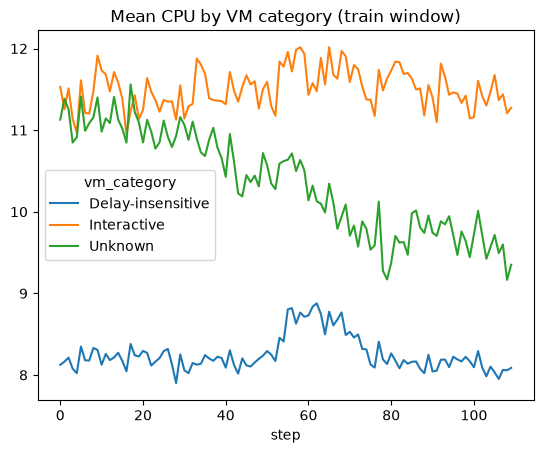

In [26]:
seg = d.groupby(["step", "vm_category"])["avg_cpu"].mean().unstack()
seg.plot(title="Mean CPU by VM category (train window)"); plt.show()

In [27]:
hi = train["cpu_mean"].quantile(0.90)
lo = train["cpu_mean"].quantile(0.10)
peaks = train[train["cpu_mean"] >= hi]
lows = train[train["cpu_mean"] <= lo]
print("peak threshold:", hi, "-> steps", list(peaks.index))
print("low threshold:", lo, "-> steps", list(lows.index))

peak threshold: 9.668361517488389 -> steps [55, 56, 57, 58, 59, 61, 62, 63, 65, 67, 68]
low threshold: 9.17919777090891 -> steps [4, 16, 28, 76, 88, 91, 100, 103, 106, 108, 109]


In [28]:
print(train.loc[peaks.index, ["active_vm_count", "cpu_mean", "cpu_p95"]])
print(train[["active_vm_count", "cpu_mean"]].corr())

      active_vm_count  cpu_mean    cpu_p95
step                                      
55              10000  9.912175  40.432884
56              10000  9.853998  39.555734
57              10000  9.802439  40.067214
58              10000  9.906192  40.360212
59              10000  9.839981  40.959595
61              10000  9.790885  40.227193
62              10000  9.772086  39.746240
63              10000  9.815904  40.490390
65              10000  9.891946  40.946022
67              10000  9.672452  40.018828
68              10000  9.842210  41.170150
                 active_vm_count  cpu_mean
active_vm_count              NaN       NaN
cpu_mean                     NaN       1.0
